# 接续时间间隔统计

写入日期：2026-10-20；修改日期：2026-10-20。本次修改：在全部接续统计之外，增加一级、多级接续的分年及三年合计柱状图和P10—P90；输入、天数分组及原有结果不变。

## 1 说明

输入为Data/04_城市链路数据中的2021—2023年三份“筛选接续”，时间范围为每年5月1日至6月25日。它们已排除负时间间隔和起终点相同的行；本次包含全部城市、全部边级、回访与回流，不限81城、不按农机或城市对去重，每条接续计1次，三年分别统计。

时间间隔=终点进入时间−起点离开时间。非负间隔按天向上取整，最少记1天：0—24小时记1天，超过24至48小时记2天，依此类推。这是显示分组，不新增最大时间间隔筛选。多级接续可能经过中间城市，不能把该间隔理解为实际行车时间。

保留全部接续的三个CSV和四张柱状图，另增加分级统计、分级分位数两个CSV和八张柱状图，均放在Results/00_数据审计；不输出逐边大表。三年合计直接合并全部接续记录的分布，不生成跨年接续，也不取三个年份的等权平均。代码位置按用户要求放在第一步，但必须先有第二步筛选接续。

分位数按整数间隔天数计算：P10取累计记录数首次达到全部记录10%的天数，P20—P90同理。对应从小到大排序后第ceil(p×样本量)条记录的天数，不做线性插值。同一天对应多个分位数时合并标记。分位数只描述分布，不作为新的研究筛选阈值。

分类只使用已有“边级”：一级接续为边级=1，多级接续为边级>1。例如A→B→C中，A→B是一级，A→C是二级，归入多级。多级接续合并统计全部二级及以上，不再逐级拆图；不重新计算边级。各类占比的分母是该类、该年份（或三年合计）的全部记录数。

## 2 参数

只依赖pandas、numpy、Matplotlib。默认不覆盖现有同名结果；明确重跑时设置GAP_DAYS_ALLOW_OVERWRITE=1。普通重跑不自动归档。

In [1]:
from pathlib import Path
import hashlib
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker

project_root = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / 'README.md').is_file() and (path / 'Data').is_dir()), None)
if project_root is None:
    raise FileNotFoundError('请从项目根目录或本Notebook所在目录运行。')
years = [2021, 2022, 2023]
input_paths = {year: project_root / f'Data/04_城市链路数据/{year}年筛选接续.csv' for year in years}
result_dir = project_root / 'Results/00_数据审计'
table_path = result_dir / '接续间隔统计.csv'
figure_paths = {str(year): result_dir / f'{year}年接续间隔.png' for year in years}
figure_paths['三年合计'] = result_dir / '三年接续间隔.png'
combined_table_path = result_dir / '三年接续间隔统计.csv'
quantile_table_path = result_dir / '接续间隔分位数.csv'
edge_types = ['一级接续', '多级接续']
type_table_path = result_dir / '分级接续间隔统计.csv'
type_quantile_table_path = result_dir / '分级接续间隔分位数.csv'
type_figure_paths = {
    (edge_type, group_name): result_dir / f"{'三年' if group_name == '三年合计' else group_name + '年'}{edge_type}间隔.png"
    for edge_type in edge_types for group_name in [*map(str, years), '三年合计']
}
manifest_path = project_root / 'Data/data_manifest.csv'
notebook_relative = 'Code/01_轨迹转城市接续/analyze_succession_days.ipynb'
allow_overwrite = os.getenv('GAP_DAYS_ALLOW_OVERWRITE', '0') == '1'
if not allow_overwrite and any(path.exists() for path in [table_path, combined_table_path, quantile_table_path, type_table_path, type_quantile_table_path,
                                                                        *figure_paths.values(), *type_figure_paths.values()]):
    raise FileExistsError('同名结果已存在；确认重跑时设置GAP_DAYS_ALLOW_OVERWRITE=1。')

def fingerprint(path):
    with open(path, 'rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

def count_days(seconds):
    # 向上取整，0秒也按用户要求计为1天。
    return np.maximum(1, np.ceil(np.asarray(seconds) / 86400)).astype('int64')

## 3 读取

只读清单中标为正式的三份筛选接续，核对文件指纹、行数、必要字段和年份。必要字段缺失、负间隔或同城端点出现时停止，不填补，也不在本步骤追加清洗。

In [2]:
manifest = pd.read_csv(manifest_path, encoding='utf-8-sig', dtype='string')
assert not manifest['relative_path'].duplicated().any(), '清单路径重复。'
input_columns = ['边记录编号', '年份', '起点城市', '终点城市',
                 '起点离开时间', '终点进入时间', '时间间隔小时', '边级']
year_records = {}
input_hashes = {}
for year, path in input_paths.items():
    relative = path.relative_to(project_root).as_posix()
    entry = manifest.loc[manifest['relative_path'].eq(relative)]
    assert len(entry) == 1 and entry.iloc[0]['formal_status'] == '正式', f'{year}年输入未登记为正式。'
    entry = entry.iloc[0]
    input_hashes[year] = fingerprint(path)
    assert input_hashes[year] == entry['sha256'], f'{year}年输入文件指纹不符。'
    records = pd.read_csv(path, usecols=input_columns, dtype='string', encoding='utf-8-sig')
    assert len(records) == int(entry['row_count']), f'{year}年输入行数不符。'
    assert not records.isna().any().any() and not records.apply(lambda column: column.str.strip().eq('')).any().any(), '必要字段缺失。'
    assert records['年份'].eq(str(year)).all() and not records['边记录编号'].duplicated().any()
    assert records['起点城市'].str.strip().ne(records['终点城市'].str.strip()).all(), '筛选接续中仍含同城端点。'
    edge_level = pd.to_numeric(records['边级'], errors='raise')
    assert np.isfinite(edge_level).all() and edge_level.ge(1).all() and edge_level.mod(1).eq(0).all(), '边级必须为正整数。'
    records['边级'] = edge_level.astype('int64')
    year_records[year] = records

## 4 处理

从原时间戳计算间隔，并核对已有“时间间隔小时”。统计表为每年每个整数天数的记录数和占比；没有记录的天数计数为0，不是填补原始缺失值。

三年合计按每个间隔天数把三年的计数相加。P10—P90采用整数天数的累计比例首次达标值，不平均各年分位数，也不按衰减权重加权。

同时按边级=1和边级>1拆开计数；两类在每个天数相加必须等于全部接续。各类三年合计仍直接加总三年计数，P10—P90使用同一计算方法。

In [3]:
daily_counts = {}
year_totals = {}
type_group_counts = {}
for year, records in year_records.items():
    source_exit = pd.to_datetime(records['起点离开时间'], errors='raise')
    target_entry = pd.to_datetime(records['终点进入时间'], errors='raise')
    assert source_exit.dt.year.eq(year).all() and target_entry.dt.year.eq(year).all()
    gap_seconds = (target_entry - source_exit).dt.total_seconds()
    assert np.isfinite(gap_seconds).all() and gap_seconds.ge(0).all(), '出现负间隔或无效时间。'
    assert np.allclose(gap_seconds / 3600, pd.to_numeric(records['时间间隔小时']), rtol=0, atol=1e-9)
    gap_days = pd.Series(count_days(gap_seconds))
    daily_counts[year] = gap_days.value_counts().sort_index()
    year_totals[year] = len(records)
    for edge_type in edge_types:
        selected = records['边级'].eq(1) if edge_type == '一级接续' else records['边级'].gt(1)
        assert selected.any(), f'{year}年{edge_type}没有记录，无法计算分位数。'
        type_group_counts[(edge_type, str(year))] = gap_days.loc[selected].value_counts().sort_index()
max_day = max(int(counts.index.max()) for counts in daily_counts.values())
statistics = pd.DataFrame([
    {'年份': year, '间隔天数': interval_day, '接续记录数': int(daily_counts[year].get(interval_day, 0)),
     '占本年接续比例': daily_counts[year].get(interval_day, 0) / year_totals[year]}
    for year in years for interval_day in range(1, max_day + 1)
])

combined_counts = statistics.groupby('间隔天数')['接续记录数'].sum()
combined_statistics = combined_counts.reset_index()
combined_statistics['占三年接续比例'] = combined_statistics['接续记录数'] / sum(year_totals.values())
group_counts = {str(year): daily_counts[year] for year in years}
group_counts['三年合计'] = combined_counts

def decile_days(counts):
    # 第ceil(k*N/10)条记录，k=1至9；整数运算避免浮点边界误差。
    quantile_ranks = (np.arange(1, 10) * int(counts.sum()) + 9) // 10
    return counts.index.to_numpy()[np.searchsorted(counts.cumsum().to_numpy(), quantile_ranks)]

quantile_statistics = pd.DataFrame([
    {'统计范围': group_name, '样本量': int(counts.sum()),
     **{f'P{level * 10}': int(value) for level, value in enumerate(decile_days(counts), start=1)}}
    for group_name, counts in group_counts.items()
])

for edge_type in edge_types:
    type_group_counts[(edge_type, '三年合计')] = sum(
        (type_group_counts[(edge_type, str(year))].reindex(range(1, max_day + 1), fill_value=0)
         for year in years)
    )
type_statistics = pd.DataFrame([
    {'接续类型': edge_type, '统计范围': group_name, '间隔天数': interval_day,
     '接续记录数': int(counts.get(interval_day, 0)),
     '占本类接续比例': counts.get(interval_day, 0) / int(counts.sum())}
    for (edge_type, group_name), counts in type_group_counts.items()
    for interval_day in range(1, max_day + 1)
]).sort_values(['接续类型', '统计范围', '间隔天数'], ignore_index=True)
type_quantile_statistics = pd.DataFrame([
    {'接续类型': edge_type, '统计范围': group_name, '样本量': int(counts.sum()),
     **{f'P{level * 10}': int(value) for level, value in enumerate(decile_days(counts), start=1)}}
    for (edge_type, group_name), counts in type_group_counts.items()
]).sort_values(['接续类型', '统计范围'], ignore_index=True)


## 5 检查

核对0小时、24小时、48小时等分组边界；每年所有天数的计数必须还原输入总数，占比之和为1。不按衰减权重加权，不只选择一级边，不裁去长间隔。

再检查三年合计逐天等于三年计数之和，分位数随百分位不减，且每个值均在累计比例首次达到对应比例的位置。

新增检查：一级和多级逐年、逐天相加与全部接续一致；每类三年合计与三个年份相加一致；每类范围内占比之和为1，P10—P90按相同排序位置计算。

In [4]:
assert count_days([0, 1, 86399, 86400, 86401, 172800, 172801]).tolist() == [1, 1, 1, 1, 2, 2, 3]
assert not statistics[['年份', '间隔天数']].duplicated().any()
assert statistics['间隔天数'].ge(1).all() and statistics['接续记录数'].ge(0).all()
for year in years:
    selected = statistics.loc[statistics['年份'].eq(year)]
    assert int(selected['接续记录数'].sum()) == year_totals[year]
    assert np.isclose(selected['占本年接续比例'].sum(), 1, rtol=0, atol=1e-12)
assert int(combined_counts.sum()) == sum(year_totals.values())
assert np.isclose(combined_statistics['占三年接续比例'].sum(), 1, atol=1e-12)
assert decile_days(pd.Series([2, 1, 1, 1], index=[1, 2, 3, 10])).tolist() == [1, 1, 1, 1, 2, 2, 3, 3, 10]
for counts in [*group_counts.values(), *type_group_counts.values()]:
    values = decile_days(counts)
    assert np.all(np.diff(values) >= 0)
    for level, value in enumerate(values, start=1):
        rank = (level * int(counts.sum()) + 9) // 10
        assert int(counts.loc[counts.index < value].sum()) < rank <= int(counts.loc[counts.index <= value].sum())
assert not type_statistics[['接续类型', '统计范围', '间隔天数']].duplicated().any()
for group_name, counts in group_counts.items():
    split_sum = sum(type_group_counts[(edge_type, group_name)].reindex(range(1, max_day + 1), fill_value=0)
                    for edge_type in edge_types)
    assert split_sum.equals(counts.reindex(range(1, max_day + 1), fill_value=0))
for edge_type in edge_types:
    assert int(type_group_counts[(edge_type, '三年合计')].sum()) == sum(
        int(type_group_counts[(edge_type, str(year))].sum()) for year in years)
assert np.allclose(type_statistics.groupby(['接续类型', '统计范围'])['占本类接续比例'].sum(), 1, rtol=0, atol=1e-12)
print('输入、天数边界、分年及合计数量、分类计数与P10—P90分位数检查通过。')

输入、天数边界、分年及合计数量、分类计数与P10—P90分位数检查通过。


## 6 输出

三个年份和三年合计各显示一张独立柱状图，虚线及上方标记为P10—P90。多个分位数位于同一天时合并标记，一级图标签分四层、其他图分三层排列，避免相互遮挡。横轴为整数间隔天数，纵轴为记录数（条）；分年图共用纵轴范围，三年合计图单独设置纵轴范围，均从0开始。分位数表同图一致，单位为天。

一级和多级各新增四张独立图（2021、2022、2023、三年合计），每张都标P10—P90。同一类的三张分年图共用纵轴范围；不同类和合计图可以使用不同纵轴范围，不可仅凭柱高跨类比较。全部图的横轴范围一致。

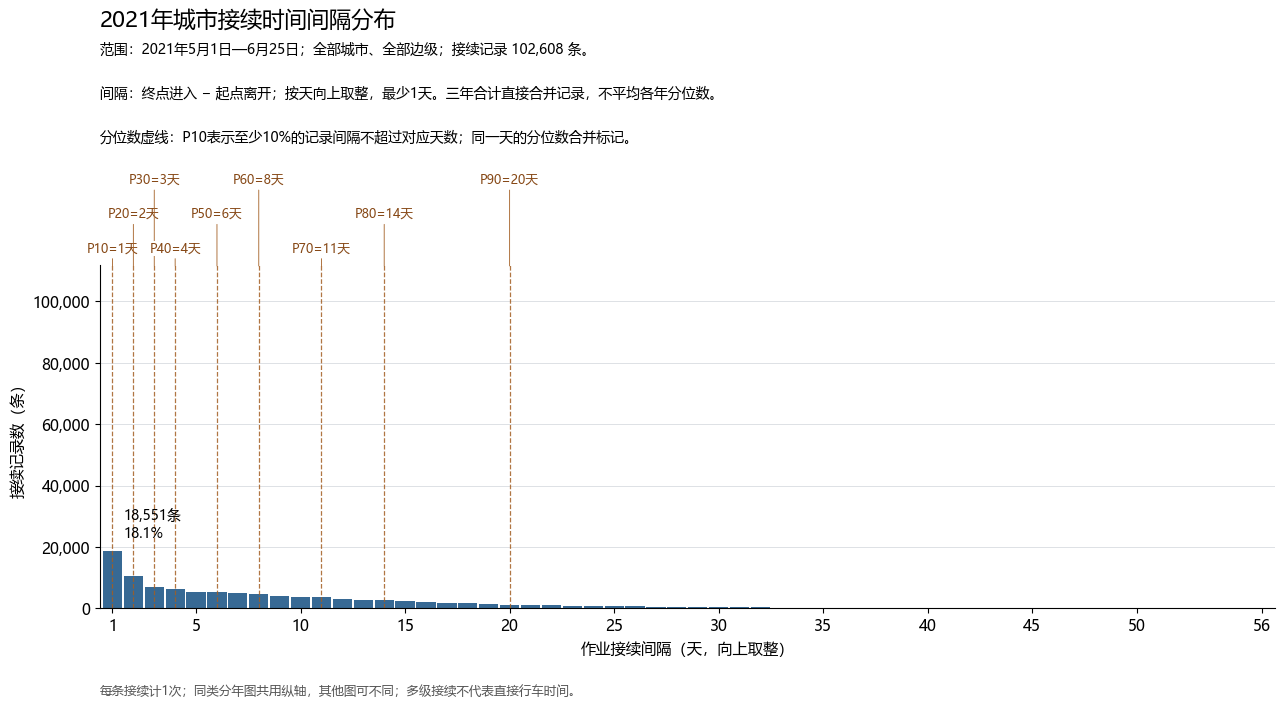

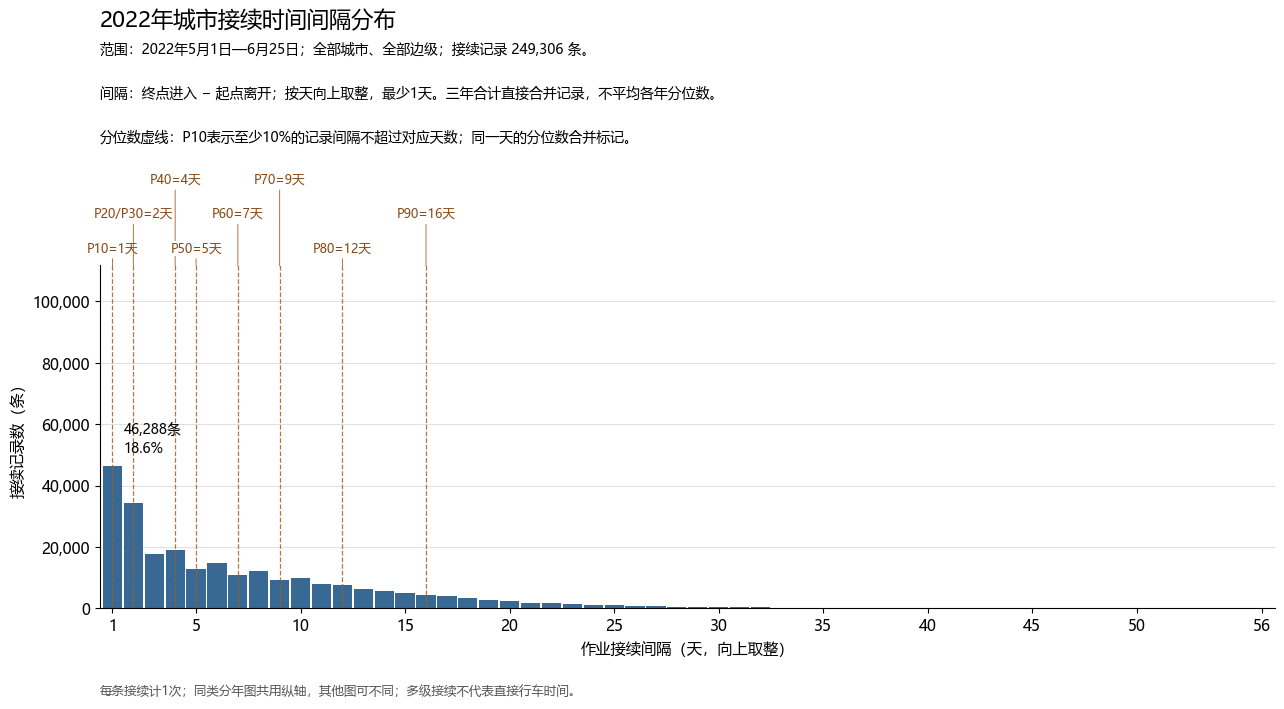

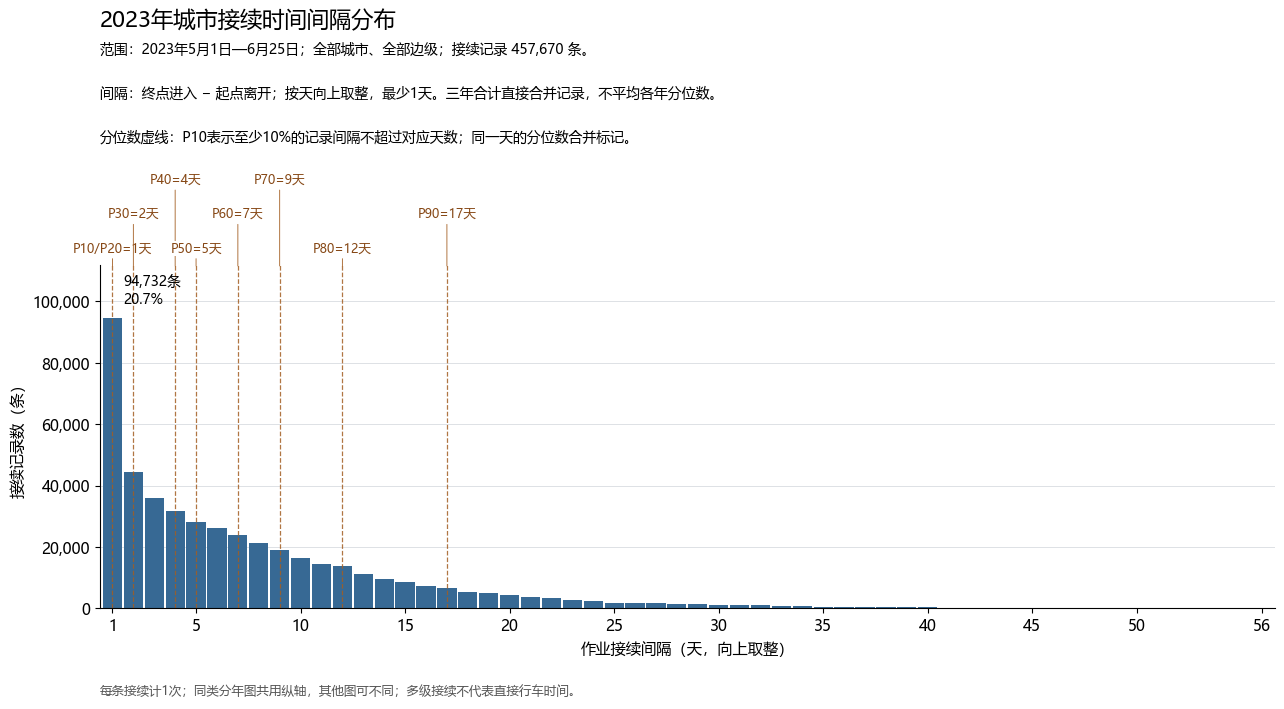

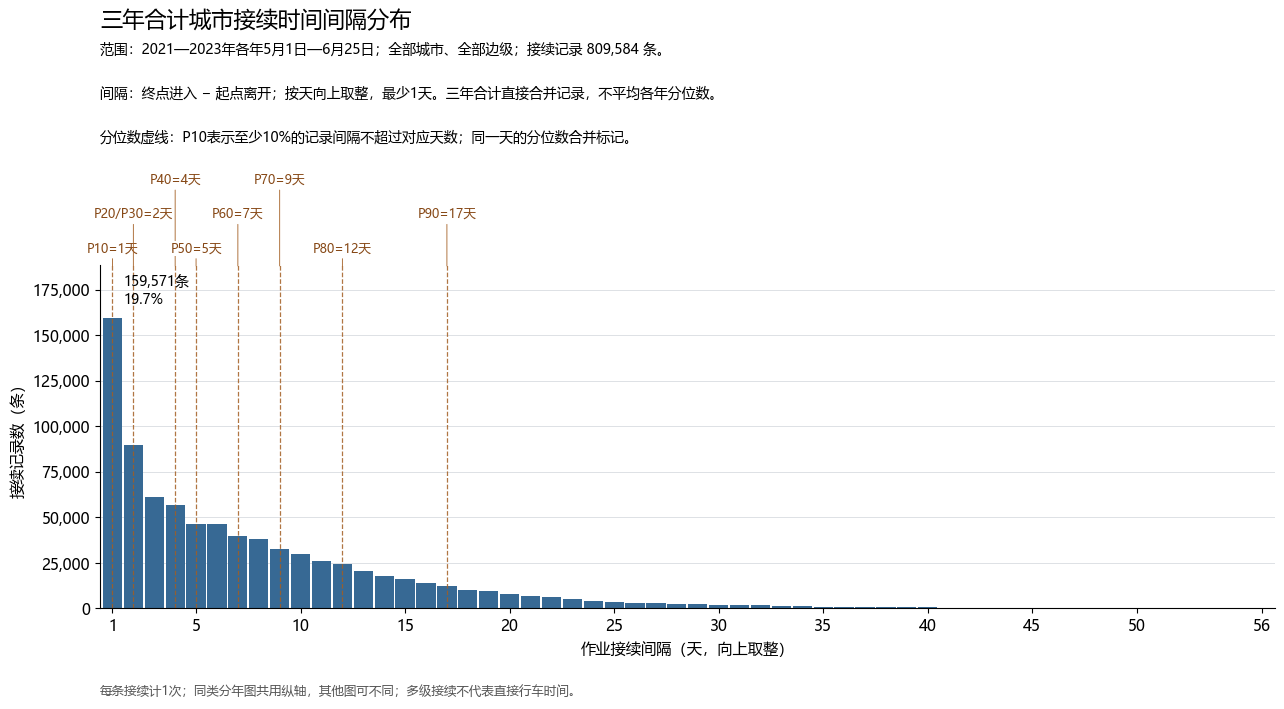

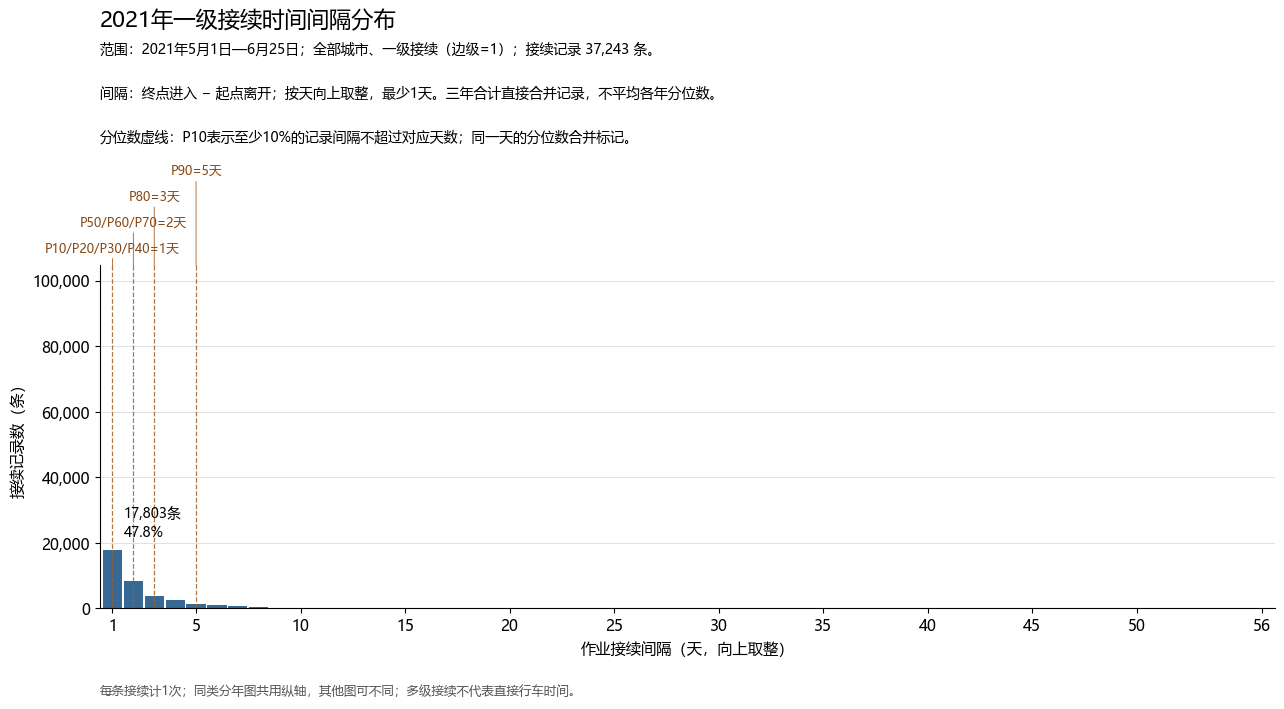

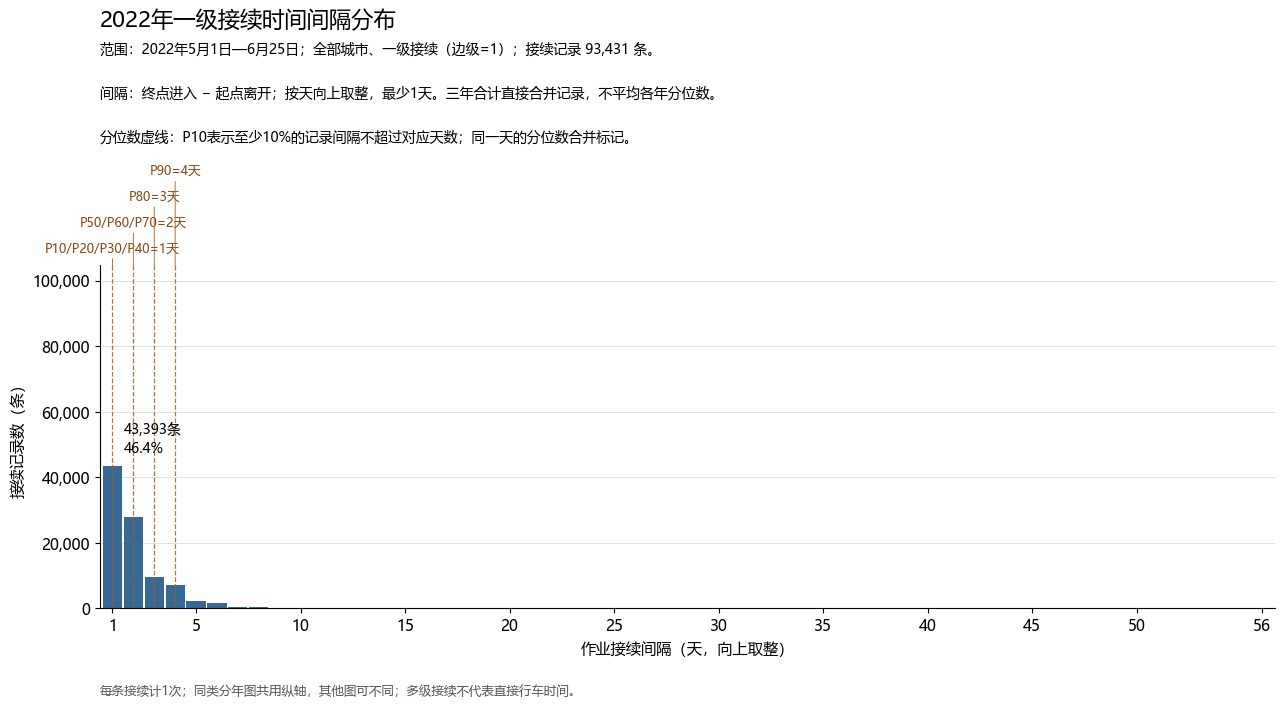

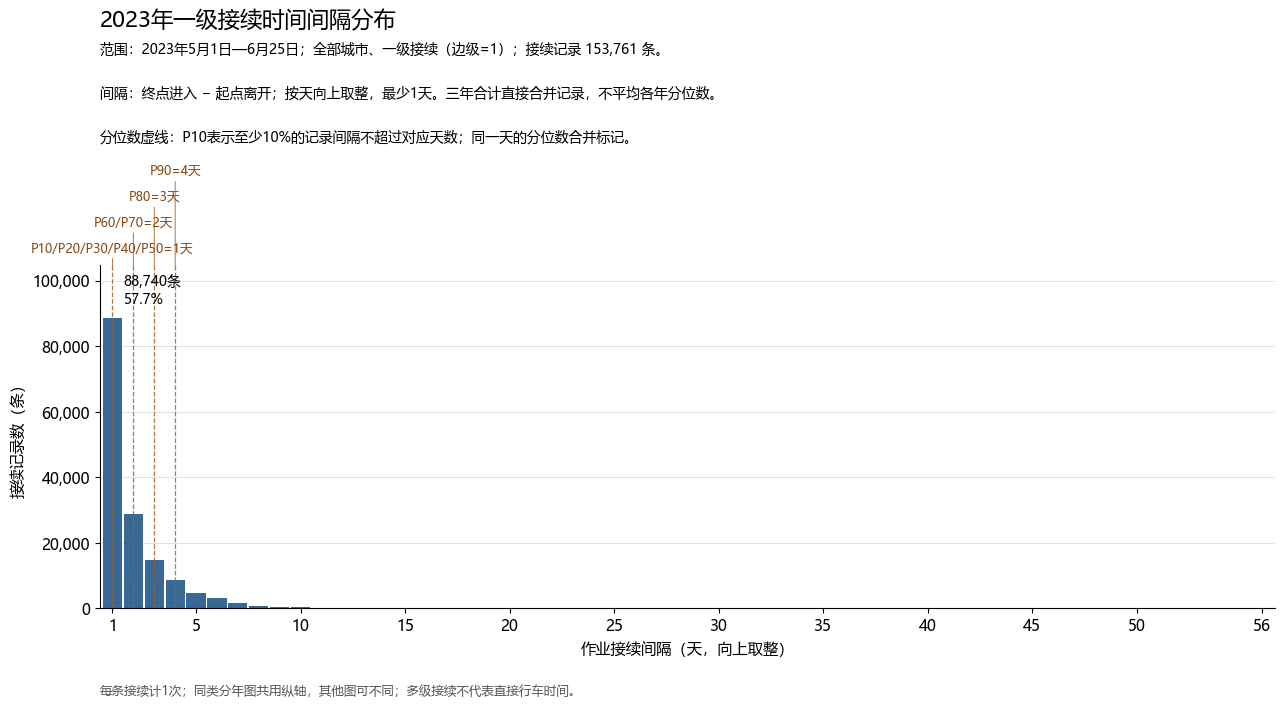

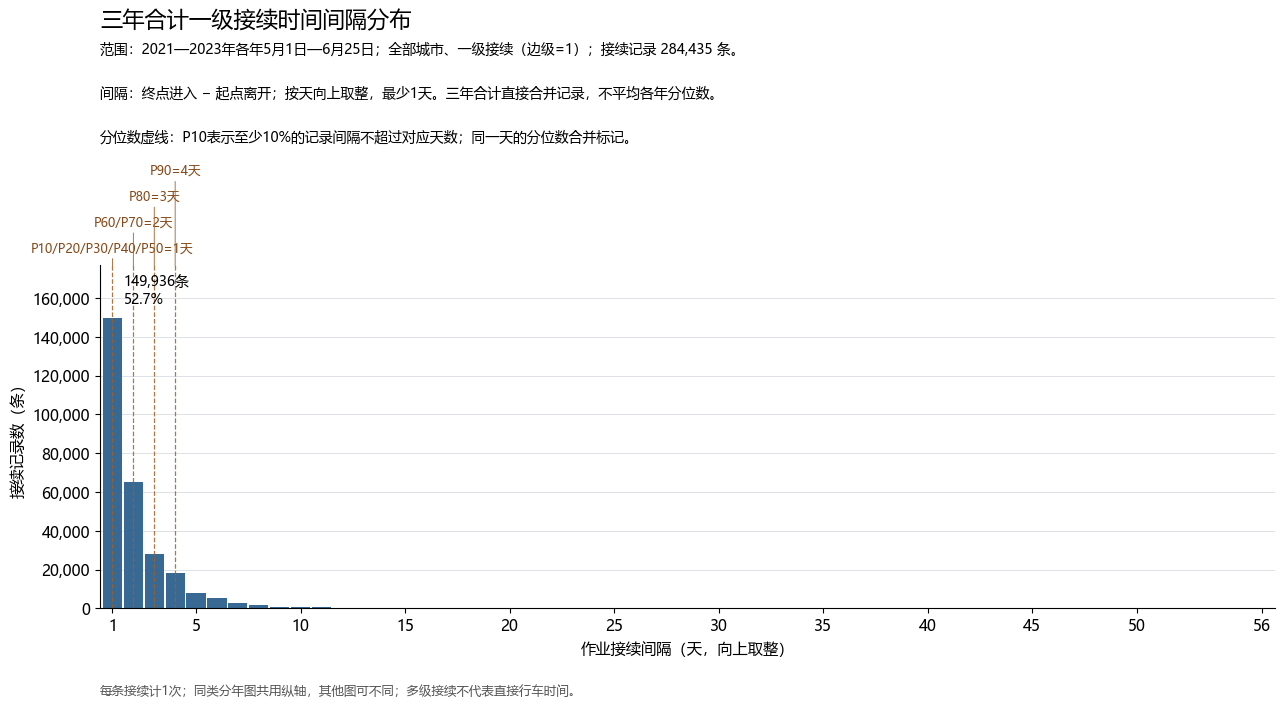

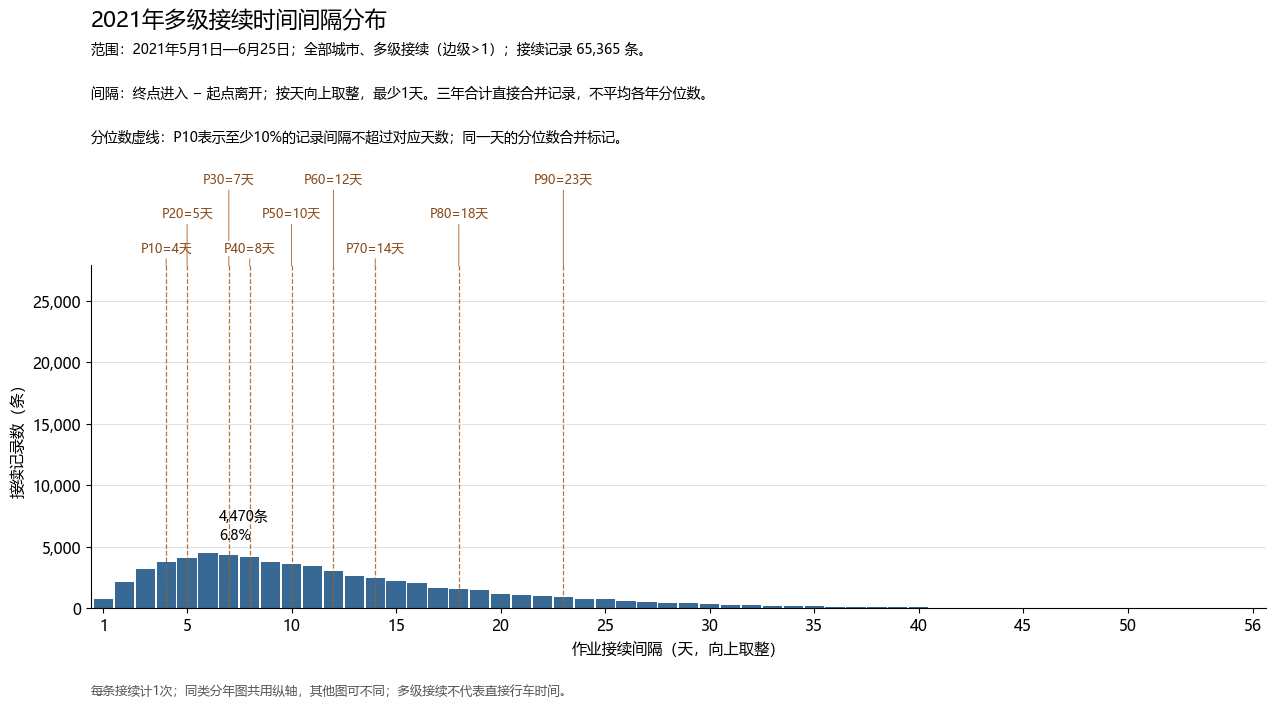

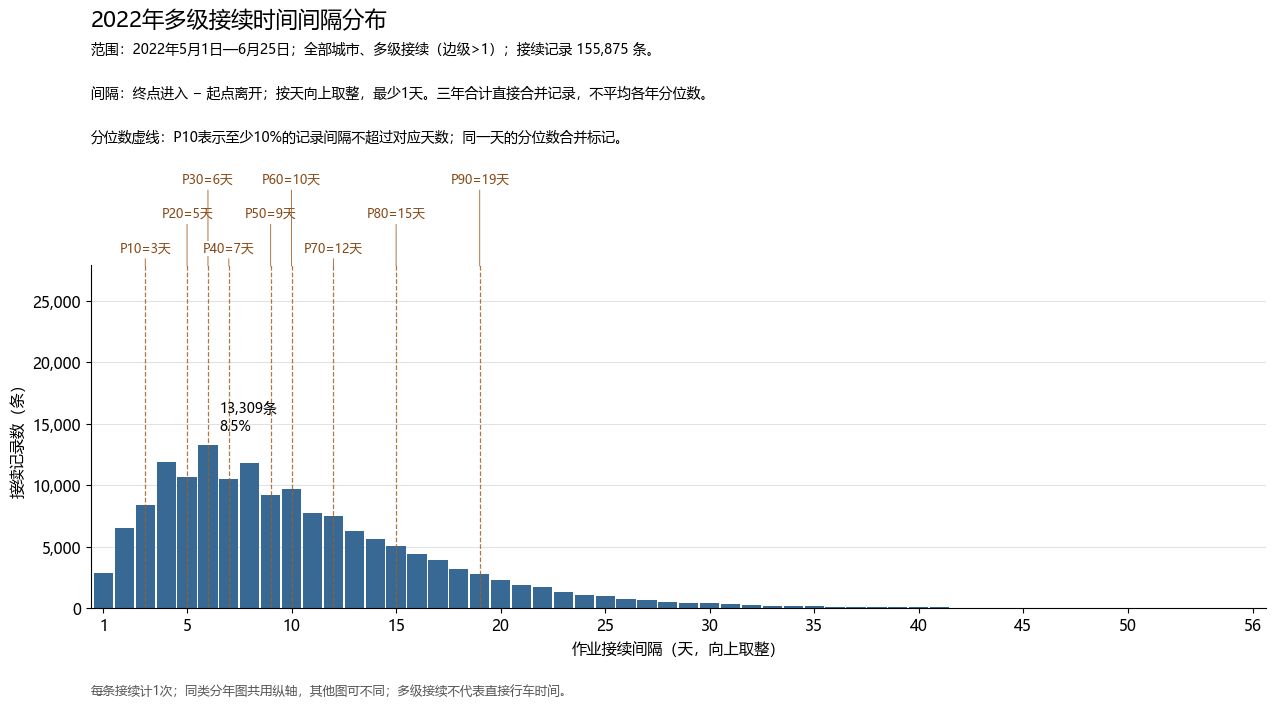

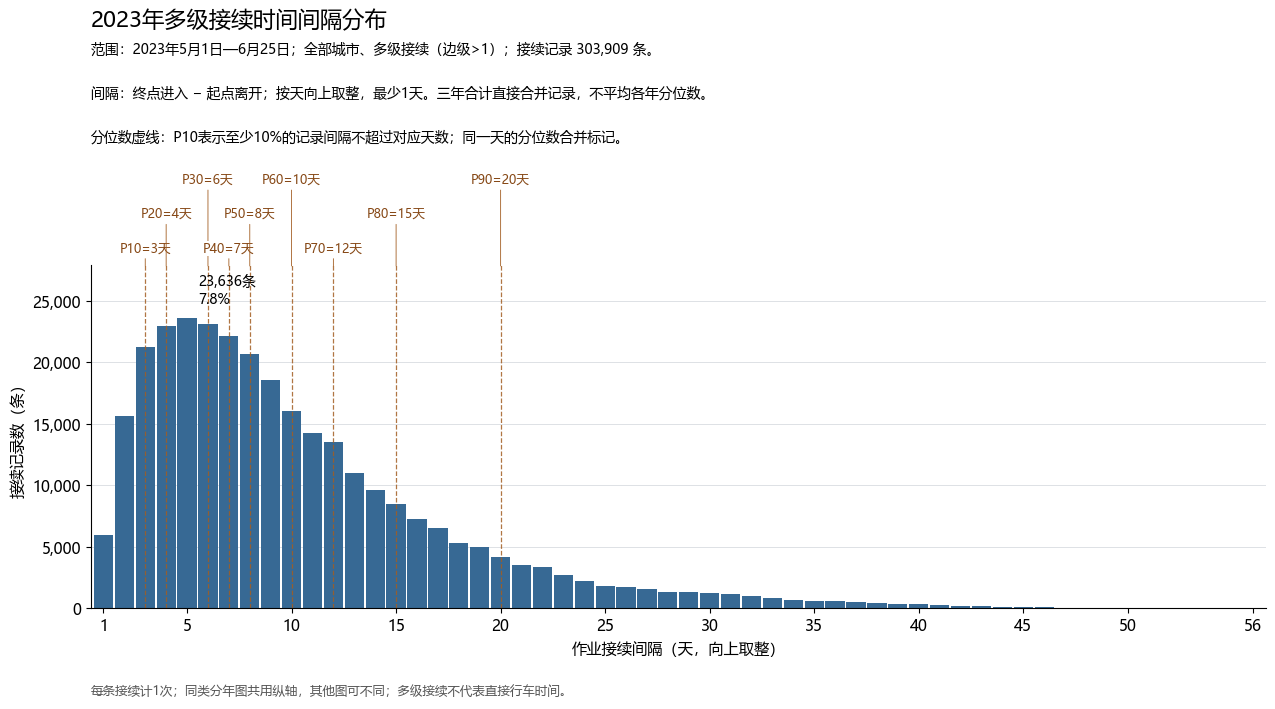

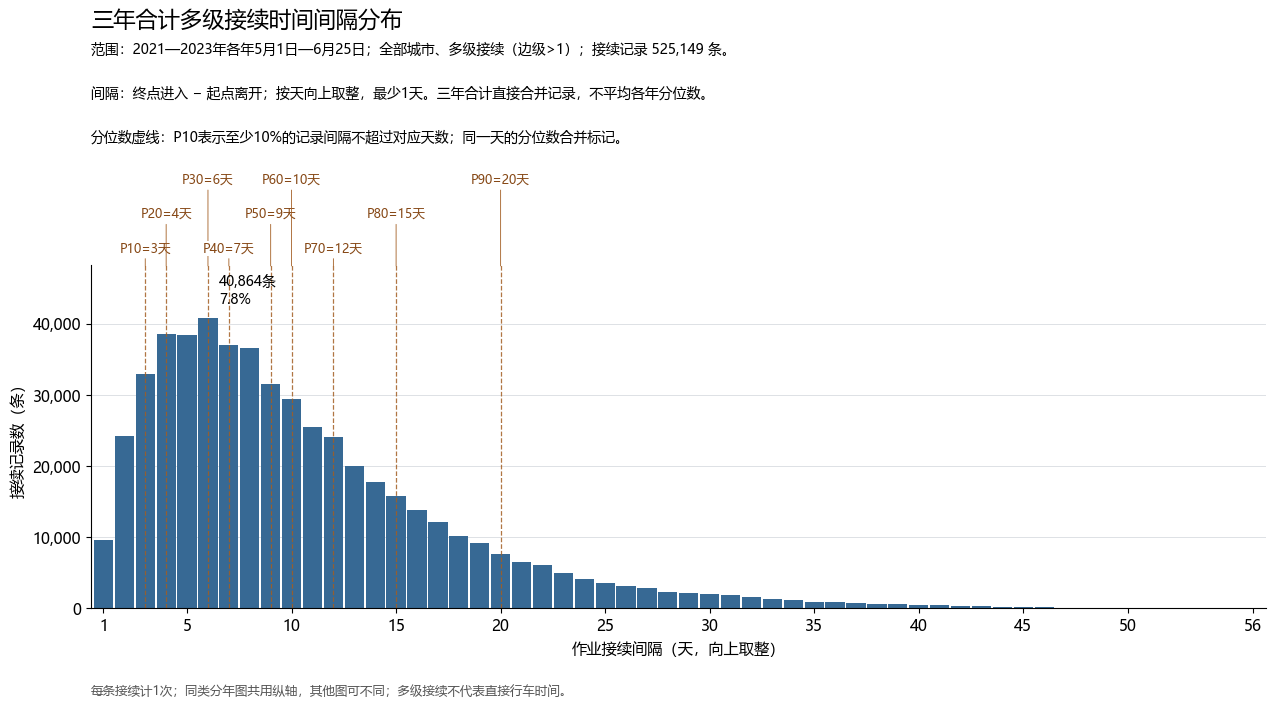

,统计范围,样本量,P10,P20,P30,P40,P50,P60,P70,P80,P90
0,2021,102608,1,2,3,4,6,8,11,14,20
1,2022,249306,1,2,2,4,5,7,9,12,16
2,2023,457670,1,1,2,4,5,7,9,12,17
3,三年合计,809584,1,2,2,4,5,7,9,12,17


,接续类型,统计范围,样本量,P10,P20,P30,P40,P50,P60,P70,P80,P90
0,一级接续,2021,37243,1,1,1,1,2,2,2,3,5
1,一级接续,2022,93431,1,1,1,1,2,2,2,3,4
2,一级接续,2023,153761,1,1,1,1,1,2,2,3,4
3,一级接续,三年合计,284435,1,1,1,1,1,2,2,3,4
4,多级接续,2021,65365,4,5,7,8,10,12,14,18,23
5,多级接续,2022,155875,3,5,6,7,9,10,12,15,19
6,多级接续,2023,303909,3,4,6,7,8,10,12,15,20
7,多级接续,三年合计,525149,3,4,6,7,9,10,12,15,20


In [5]:
result_dir.mkdir(parents=True, exist_ok=True)
for output, path in [(statistics, table_path), (combined_statistics, combined_table_path),
                     (quantile_statistics, quantile_table_path), (type_statistics, type_table_path),
                     (type_quantile_statistics, type_quantile_table_path)]:
    output.to_csv(path, index=False, encoding='utf-8-sig')
    pd.testing.assert_frame_equal(pd.read_csv(path, encoding='utf-8-sig'), output, check_dtype=False)
fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next((name for name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC'] if name in fonts), None)
if chinese_font is None:
    raise RuntimeError('缺少中文字体，需安装微软雅黑、黑体或Noto Sans CJK SC后重跑。')
plt.rcParams.update({'font.sans-serif': [chinese_font], 'axes.unicode_minus': False, 'font.size': 11})
ticks = sorted({1, max_day, *range(5, max_day - 1, 5)})
shared_upper = statistics['接续记录数'].max() * 1.18
plot_groups = [('全部接续', group_name, counts, figure_paths[group_name], shared_upper)
               for group_name, counts in group_counts.items()]
for edge_type in edge_types:
    type_upper = max(type_group_counts[(edge_type, str(year))].max() for year in years) * 1.18
    plot_groups.extend((edge_type, group_name, counts, type_figure_paths[(edge_type, group_name)], type_upper)
                       for (selected_type, group_name), counts in type_group_counts.items() if selected_type == edge_type)
for edge_type, group_name, counts, figure_path, annual_upper in plot_groups:
    is_combined = group_name == '三年合计'
    total = int(counts.sum())
    upper = counts.max() * 1.18 if is_combined else annual_upper
    fig, ax = plt.subplots(figsize=(13.2, 7.3))
    fig.subplots_adjust(left=0.09, right=0.98, bottom=0.16, top=0.63)
    title = '三年合计城市接续时间间隔分布' if is_combined else f'{group_name}年城市接续时间间隔分布'
    if edge_type != '全部接续':
        title = title.replace('城市接续', edge_type)
    fig.suptitle(title, x=0.09, y=0.98, ha='left', fontsize=16)
    period = '2021—2023年各年5月1日—6月25日' if is_combined else f'{group_name}年5月1日—6月25日'
    scope = {'全部接续': '全部边级', '一级接续': '一级接续（边级=1）', '多级接续': '多级接续（边级>1）'}[edge_type]
    fig.text(0.09, 0.92, f'范围：{period}；全部城市、{scope}；接续记录 {total:,} 条。', fontsize=10)
    fig.text(0.09, 0.86, '间隔：终点进入 − 起点离开；按天向上取整，最少1天。三年合计直接合并记录，不平均各年分位数。', fontsize=10)
    fig.text(0.09, 0.80, '分位数虚线：P10表示至少10%的记录间隔不超过对应天数；同一天的分位数合并标记。', fontsize=10)
    ax.bar(counts.index, counts.values, width=0.92, color='#376994')
    ax.set(xlabel='作业接续间隔（天，向上取整）', ylabel='接续记录数（条）',
           xlim=(0.4, max_day + 0.6), ylim=(0, upper), xticks=ticks)
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#d8dce0', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    quantile_labels = {}
    for level, value in enumerate(decile_days(counts), start=1):
        quantile_labels.setdefault(int(value), []).append(f'P{level * 10}')
    for index, (value, labels) in enumerate(quantile_labels.items()):
        ax.axvline(value, color='#a35e22', linestyle='--', linewidth=0.9, alpha=0.85)
        ax.annotate('/'.join(labels) + f'={value}天', xy=(value, 0.99), xycoords=('data', 'axes fraction'),
                    xytext=(value, 1.03 + (index % 4) * 0.075 if edge_type == '一级接续' else 1.03 + (index % 3) * 0.10), textcoords=('data', 'axes fraction'),
                    ha='center', va='bottom', fontsize=9, color='#874917', annotation_clip=False,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.6}, zorder=5,
                    arrowprops={'arrowstyle': '-', 'color': '#a35e22', 'lw': 0.6, 'zorder': 2})
    peak_day = int(counts.idxmax())
    ax.annotate(f'{int(counts.max()):,}条\n{counts.max() / total:.1%}', (peak_day, counts.max()),
                xytext=(8, 7), textcoords='offset points', ha='left', va='bottom', fontsize=10)
    fig.text(0.09, 0.04, '每条接续计1次；同类分年图共用纵轴，其他图可不同；多级接续不代表直接行车时间。', fontsize=9, color='#555555')
    fig.savefig(figure_path, dpi=170, facecolor='white')
    plt.show()
    plt.close(fig)
display(quantile_statistics)
display(type_quantile_statistics)

In [6]:
# 只更新本Notebook的五个统计表登记；原始接续不改。
manifest_records = []
for file_id, path, data, grain, purpose, note in [
    ('SUCCESSION_GAP_DAYS', table_path, statistics, '一行一个年份与整数间隔天数',
     '查看全部已筛选接续的分年间隔分布', '三年分别统计'),
    ('SUCCESSION_GAP_DAYS_COMBINED', combined_table_path, combined_statistics, '一行一个整数间隔天数',
     '查看全部已筛选接续的三年合计间隔分布', '三年计数直接求和；不是各年占比的平均'),
    ('SUCCESSION_GAP_QUANTILES', quantile_table_path, quantile_statistics, '一行一个年份或三年合计范围',
     '查看三个年份与三年合计的P10至P90', '分位数为累计比例首次达到目标的整数天数；合计分位数不平均各年分位数'),
    ('SUCCESSION_GAP_DAYS_BY_LEVEL', type_table_path, type_statistics, '一行一个接续类型、统计范围与整数间隔天数',
     '分开查看一级和多级接续的分年及三年合计间隔分布', '一级=边级1；多级=边级大于1；占比以本类本范围记录数为分母'),
    ('SUCCESSION_GAP_QUANTILES_BY_LEVEL', type_quantile_table_path, type_quantile_statistics, '一行一个接续类型与年份或三年合计范围',
     '分开查看一级和多级接续的分年及合计P10至P90', '一级=边级1；多级=边级大于1；合计直接合并三年记录；分位数不插值'),
]:
    manifest_records.append({
        'file_id': file_id, 'relative_path': path.relative_to(project_root).as_posix(),
        'file_name': path.name, 'file_role': 'descriptive_output', 'formal_status': '正式',
        'read_only': 'false', 'year': '2021-2023', 'time_range': '各年05-01至06-25',
        'data_grain': grain, 'row_count': str(len(data)), 'file_size_bytes': str(path.stat().st_size),
        'sha256': fingerprint(path), 'encoding': 'UTF-8-SIG', 'source_or_generator': notebook_relative,
        'upstream': '；'.join(path.relative_to(project_root).as_posix() for path in input_paths.values()),
        'purpose': purpose, 'notes': '全部城市与边级；每条计1；向上取整且至少1天；' + note,
    })
new_entries = pd.DataFrame(manifest_records, columns=manifest.columns)
updated_manifest = pd.concat([manifest.loc[~manifest['file_id'].isin(new_entries['file_id'])], new_entries], ignore_index=True)
assert not updated_manifest['file_id'].duplicated().any() and not updated_manifest['relative_path'].duplicated().any()
for year, path in input_paths.items():
    assert fingerprint(path) == input_hashes[year], '输入在运行期间发生变化。'
updated_manifest.to_csv(manifest_path, index=False, encoding='utf-8-sig')
for path in [table_path, combined_table_path, quantile_table_path, type_table_path, type_quantile_table_path]:
    assert path.read_bytes()[:3] == b'\xef\xbb\xbf'
assert all(path.is_file() and path.stat().st_size > 0 for path in [*figure_paths.values(), *type_figure_paths.values()])
print(f'完成：三年共{sum(year_totals.values()):,}条接续；五个统计CSV和十二张含P10—P90标记的柱状图（新增两类各四张）。')

完成：三年共809,584条接续；五个统计CSV和十二张含P10—P90标记的柱状图（新增两类各四张）。
